In [ ]:
!pip install --upgrade binance-historical-data plotly -q

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

In [ ]:
def create_data_dumper(market_type="spot", data_frequency="1h"):
    return BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class=market_type,
        data_type="klines",
        data_frequency=data_frequency,
    )

def get_list_all_trading_pairs(market_type="spot"):
    data_dumper = create_data_dumper(market_type)
    return data_dumper.get_list_all_trading_pairs()

def find_first_data_date(ticker, market_type="spot"):
    data_dumper = create_data_dumper(market_type)
    return data_dumper.get_min_start_date_for_ticker(ticker)

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h", market_type="spot"):
    data_dumper = create_data_dumper(market_type, data_frequency)

    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()

    data_dumper.dump_data(
        tickers=ticker,
        date_start=date_start,
        date_end=date_end,
        is_to_update_existing=False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency="1h", market_type="spot"):
    base_path = f"{market_type}"

    daily_path = os.path.join(os.getcwd(), f"{base_path}/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"{base_path}/monthly/klines/{ticker}/{data_frequency}")

    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)

    all_files = daily_files + monthly_files

    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker} ({market_type})")
        return None

    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)

    return data

In [ ]:
tickers = ["BTCUSDT","ETHUSDT","XPRUSDT","BNBUSDT","SOLUSDT","TRXUSDT","DOGEUSDT","ADAUSDT"]

In [ ]:
tickers = ["BTCUSDT","ETHUSDT","XRPUSDT","BNBUSDT","SOLUSDT","TRXUSDT","DOGEUSDT","ADAUSDT"]
data = {}
for ticker in tickers:
    data_frequency = '1h'
    download_ticker(ticker, "2019-01-01", "2025-11-27", data_frequency, market_type="spot")
    data[ticker] = process_csv_files(ticker, data_frequency)
    data[ticker] = data[ticker].drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])

data


---> Found overall tickers: 3556
---> Filter to asked tickers: 7
------> Tickers left: 4
Download full data for 4 tickers: 
---> Data will be saved here: D:\spot
---> Data Frequency: 1h
---> Start Date: 20190101
---> End Date: 20251127


Tickers:   0%|          | 0/4 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

...

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 3 tickers:
---> For ADAUSDT new data saved for: 0 months 0 days
---> For AUSDT new data saved for: 0 months 0 days
---> For ADAU new data saved for: 0 months 0 days


{'BTCUSDT':               open_time      Open      High       Low     Close      volume
 644 2017-08-17 05:00:00   4308.83   4328.69   4291.37   4315.32   23.234916
 645 2017-08-17 06:00:00   4330.29   4345.45   4309.37   4324.35    7.229691
 646 2017-08-17 07:00:00   4316.62   4349.99   4287.41   4349.99    4.443249
 647 2017-08-17 08:00:00   4333.32   4377.85   4333.32   4360.69    0.972807
 648 2017-08-17 09:00:00   4360.00   4445.78   4360.00   4444.00   10.763623
 ..                  ...       ...       ...       ...       ...         ...
 639 2025-11-27 19:00:00  91791.99  91791.99  91506.94  91528.21  363.777860
 640 2025-11-27 20:00:00  91528.22  91596.76  91400.00  91433.17  259.279010
 641 2025-11-27 21:00:00  91433.18  91600.00  91217.17  91416.99  272.081510
 642 2025-11-27 22:00:00  91416.99  91590.00  91114.52  91317.65  289.903540
 643 2025-11-27 23:00:00  91317.66  91566.00  91213.79  91333.95  269.527580
 
 [72366 rows x 6 columns],
 'ETHUSDT':               open_time 

In [ ]:
df = data.copy()

# OHLC Chart
fig = go.Figure(
    data=[
        go.Candlestick(
            x=df["BTCUSDT"]["open_time"],
            open=df["BTCUSDT"]["Open"],
            high=df["BTCUSDT"]["High"],
            low=df["BTCUSDT"]["Low"],
            close=df["BTCUSDT"]["Close"],
            name="OHLC"
        )
    ]
)

# Layout config
fig.update_layout(
    title="OHLC Chart",
    xaxis_title="Time",
    yaxis_title="Price",
    xaxis_rangeslider_visible=False,
    template="plotly_dark",
    height=600
)

fig.show()

In [ ]:

#Lấy data từ 01-01-2020 tới 31-12-2024
filtered_data = {}

for ticker, df in data.items():
    df['open_time'] = pd.to_datetime(df['open_time'])
    mask = (df['open_time'] >= '2020-01-01') & (df['open_time'] <= '2024-12-31 23:59:59')
    filtered_data[ticker] = df.loc[mask].copy()

#Lấy các data đơn lẻ

import pandas as pd

def extract_ohlcv(data: dict) -> tuple:
    clean_data = {}
    for sym, df in data.items():
        clean_df = df.drop_duplicates(subset=['open_time'], keep='last')
        clean_data[sym] = clean_df.set_index('open_time')

    close_1h  = pd.DataFrame({sym: df['Close']  for sym, df in clean_data.items()})
    open_1h   = pd.DataFrame({sym: df['Open']   for sym, df in clean_data.items()})
    high_1h   = pd.DataFrame({sym: df['High']   for sym, df in clean_data.items()})
    low_1h    = pd.DataFrame({sym: df['Low']    for sym, df in clean_data.items()})
    volume_1h    = pd.DataFrame({sym: df['volume']    for sym, df in clean_data.items()})

    return close_1h, open_1h, high_1h, low_1h, volume_1h
close_1h, open_1h, high_1h, low_1h, volume_1h = extract_ohlcv(filtered_data)
traded_price = close_1h
fret = traded_price.pct_change().shift(-1)

In [ ]:



def plot_coin_pnl(alpha, future_returns, thresh=0.05):
    coin_pnl = (np.sign(alpha) * future_returns)
    coin_pnl = coin_pnl.loc[:, coin_pnl.notna().any(axis=0)]
    coin_pnl = coin_pnl.groupby(coin_pnl.index.date).sum()
    coin_ir = coin_pnl.mean() / coin_pnl.std()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    coin_ir.plot(kind='bar', ax=axes[0])
    axes[0].axhline(thresh, c='tab:orange', ls='--', label=f'% > {thresh}: {(coin_ir > thresh).mean():.2%}')
    axes[0].legend()

    coin_pnl.cumsum().plot(ax=axes[1])
    axes[1].legend(loc='upper left', bbox_to_anchor=(1.05, 1))

def plot_long_short_pnl(alpha, future_returns, ax=None):
    long_alpha = alpha.copy()
    long_alpha[long_alpha <= 0] = np.nan
    long_alpha = np.sign(long_alpha)
    long_pnl = (long_alpha * future_returns).sum(1)
    long_pnl = long_pnl.groupby(long_pnl.index.date).sum()
    long_ir = long_pnl.mean() / long_pnl.std()

    short_alpha = alpha.copy()
    short_alpha[short_alpha >= 0] = np.nan
    short_alpha = np.sign(short_alpha)
    short_pnl = (short_alpha * future_returns).sum(1)
    short_pnl = short_pnl.groupby(short_pnl.index.date).sum()
    short_ir = short_pnl.mean() / short_pnl.std()

    if ax is None:
        fig, ax = plt.subplots(1, 1)
    long_pnl.cumsum().plot(ax=ax, label=f'long ir: {long_ir.mean():.3f}')
    short_pnl.cumsum().plot(ax=ax, label=f'short ir: {short_ir.mean():.3f}')
    ax.legend()

def plot_analysis(alpha, stats_simple, pnl):
    """Gộp 2 biểu đồ thành 1 hàng ngang"""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Biểu đồ 1: Strategy PnL vs BTC
    pnl.cumsum().plot(ax=axes[0], label='Strategy PnL')
    axes[0].plot((stats_simple.future_returns['BTCUSDT']*2e7).cumsum(), alpha=0.5, color='tab:gray', label='BTC')
    axes[0].set_title('Strategy PnL vs BTC')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Biểu đồ 2: Long vs Short PnL
    plot_long_short_pnl(alpha, stats_simple.future_returns, ax=axes[1])
    axes[1].set_title('Long vs Short PnL')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


In [ ]:
import pandas as pd
import numpy as np

class StatsSimple:
    def __init__(self, alpha, future_returns, cost=0, booksize=2e7):
        self.alpha = alpha
        self.future_returns = future_returns
        self.cost = cost
        self.booksize = booksize

    def simsum(self):
        pos = self.alpha

        # PnL và Traded Value ban đầu
        coin_pnl = pos * self.future_returns * self.booksize
        traded_value = pos.diff().abs().sum(axis=1) * self.booksize
        trades_cost = traded_value * self.cost
        pnl_series = coin_pnl.sum(axis=1) - trades_cost

        daily_pnl = pnl_series.groupby(pnl_series.index.date).sum()
        daily_pnl.index = pd.to_datetime(daily_pnl.index)

        daily_traded = traded_value.groupby(traded_value.index.date).sum()
        daily_traded.index = pd.to_datetime(daily_traded.index)

        equity = self.booksize + daily_pnl.cumsum()

        def calc_metrics(pnl_slice, equity_slice, traded_slice):
            stats = pd.Series(dtype=float)
            stats['Return'] = pnl_slice.sum()/self.booksize

            # Sharpe
            sharpe = (pnl_slice.mean() / pnl_slice.std()) * np.sqrt(365) if pnl_slice.std() != 0 else 0
            stats['Sharpe'] = sharpe

            # Max Drawdown
            drawdown_pct = (equity_slice - equity_slice.cummax()) / equity_slice.cummax()
            stats['Max Drawdown (%)'] = drawdown_pct.min() * 100

            # Margin
            total_pnl = pnl_slice.sum()
            total_traded = traded_slice.sum()
            margin = total_pnl / total_traded if total_traded != 0 else 0

            stats['Margin (bps)'] = margin * 10000

            # Fitness
            stats['Fitness'] = sharpe * np.sqrt(abs(margin))

            return stats

        overall_stats = calc_metrics(daily_pnl, equity, daily_traded)
        overall_stats.name = 'Overall'

        yearly_stats = {}
        for year in daily_pnl.index.year.unique():
            mask = daily_pnl.index.year == year
            yearly_stats[year] = calc_metrics(daily_pnl[mask], equity[mask], daily_traded[mask])

        # Ghép thành DataFrame
        stats_df = pd.DataFrame(yearly_stats)
        stats_df.insert(0, 'Overall', overall_stats)

        return stats_df, pnl_series

In [ ]:
def AlphaOpNeutral(alpha):
    row_means = alpha.mean(axis=1, keepdims=True)
    return alpha - row_means


In [ ]:
import numpy as np
import pandas as pd

def generate_alpha(close_1h, open_1h, high_1h, low_1h, volume_1h, delay=1):
    close = close_1h.shift(delay)
    open = open_1h.shift(delay)
    high = high_1h.shift(delay)
    low = low_1h.shift(delay)
    volume = volume_1h.shift(delay)

    tr = high - low
    tr_ma = tr.rolling(6).mean().replace(0, np.nan)
    vol_ma = volume.rolling(6).mean().replace(0, np.nan)

    effort = volume / vol_ma
    result = tr / tr_ma

    anomaly = (effort - result).clip(lower=0)

    is_green = (close > open).astype(int)
    is_red = (close < open).astype(int)

    signal = anomaly * (is_red - is_green)

    # Chuẩn hóa
    sig_mean = signal.rolling(24).mean()
    sig_std  = signal.rolling(24).std()
    signal_z = (signal - sig_mean) / (sig_std )

    signal_z = signal_z.replace([np.inf, -np.inf], np.nan).fillna(0)
    alpha = signal_z.rank(axis=1, pct=True) - 0.5

    return np.array(alpha.rolling(2).mean())

,Return,Sharpe,Max Drawdown (%),Margin (bps),Fitness
2020,2.241,3.847,-17.922,2.239,0.058
2021,2.897,2.987,-7.994,2.852,0.050
2022,0.922,1.785,-2.851,0.913,0.017
2023,1.241,3.379,-1.572,1.219,0.037
2024,0.741,1.718,-2.966,0.734,0.015
Overall,8.042,2.628,-17.922,1.591,0.033


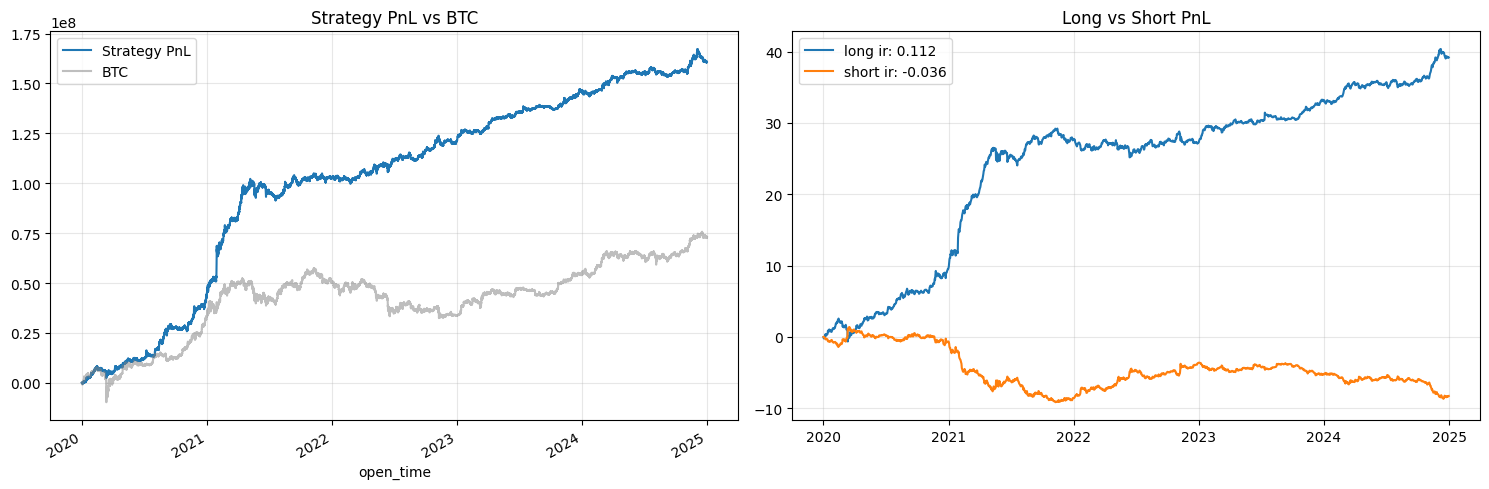

In [ ]:
alpha = generate_alpha(close_1h, open_1h, high_1h, low_1h, volume_1h, delay=1)
#alpha = AlphaOpNeutral(alpha)
alpha_df = pd.DataFrame(alpha, index=fret.index, columns=fret.columns)
# 1. Khởi tạo và tính toán
stats_simple = StatsSimple(alpha_df, fret, cost=0, booksize=2e7)
stats_df, pnl = stats_simple.simsum()


stats_df_transposed = stats_df.T
new_index_order = [idx for idx in stats_df_transposed.index if idx != 'Overall'] + ['Overall']
stats_df_final = stats_df_transposed.loc[new_index_order]
display(stats_df_final.style.format("{:,.3f}"))
plot_analysis(alpha_df, stats_simple, pnl)

,Return,Sharpe,Max Drawdown (%),Margin (bps),Fitness
2020,1.543,3.678,-11.282,1.541,0.046
2021,1.258,1.813,-8.156,1.238,0.020
2022,1.313,3.531,-2.363,1.299,0.040
2023,0.723,2.507,-2.154,0.710,0.021
2024,0.192,0.590,-3.233,0.190,0.003
Overall,5.028,2.265,-11.282,0.995,0.023


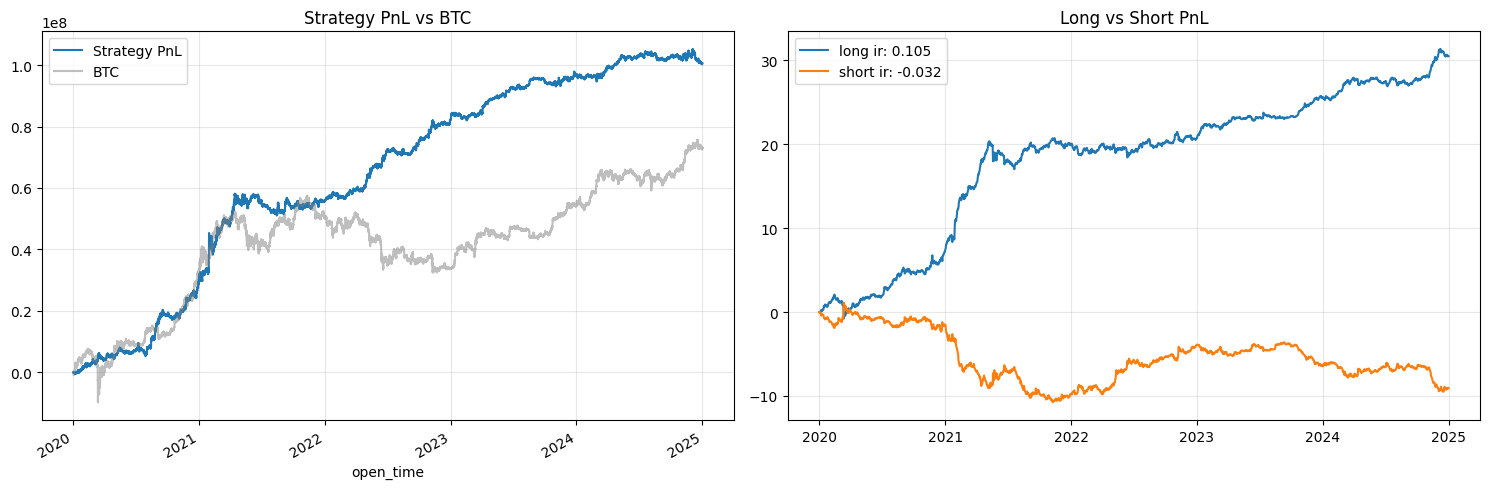

In [ ]:
#Khi có Neutral thì sẽ an toàn hơn nếu thị trường đi theo 1 chiều, tránh được những bất thường như sự kiện tháng 10 năm ngoái,
# Alpha vẫn giữ được tín hiệu tích cực drawdown thấp hơn, nhưng đổi lại margin thấp hơn và return thấp hơn
alpha = generate_alpha(close_1h, open_1h, high_1h, low_1h, volume_1h, delay=1)
alpha = AlphaOpNeutral(alpha)
alpha_df = pd.DataFrame(alpha, index=fret.index, columns=fret.columns)
# 1. Khởi tạo và tính toán
stats_simple = StatsSimple(alpha_df, fret, cost=0, booksize=2e7)
stats_df, pnl = stats_simple.simsum()


stats_df_transposed = stats_df.T
new_index_order = [idx for idx in stats_df_transposed.index if idx != 'Overall'] + ['Overall']
stats_df_final = stats_df_transposed.loc[new_index_order]
display(stats_df_final.style.format("{:,.3f}"))
plot_analysis(alpha_df, stats_simple, pnl)